# Homework 4

Name: Shanglin Jiang

GitHub Username: sjiang83-corgi

USC ID: 1967702034

In [1]:
from pathlib import Path
import csv
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.special import expit, logit
from scipy.stats import norm
from scipy.optimize import linprog
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 42
DATA_DIR = Path("../data/AReM")
RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(exist_ok=True)
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
STATISTICS = ["min", "max", "mean", "median", "std", "q1", "q3"]
SELECTED_STATS = ["mean", "std", "max"]
L_VALUES = range(1, 21)
C_VALUES = [0.01, 0.1, 1.0, 10.0, 100.0]
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
# 小样本计算只用一个 BLAS 线程，避免线程调度开销。
thread_limit = threadpool_limits(limits=1)
search_warnings = []

## Data preparation

In [2]:
def load_recording(file_path):
    data_lines = []
    for line in file_path.read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#"):
            data_lines.append(line)

    if "," in data_lines[0]:
        rows = list(csv.reader(data_lines))
        for row in rows:
            while row and row[-1].strip() == "":
                row.pop()
    else:
        rows = []
        for line in data_lines:
            rows.append(line.split())

    for row in rows:
        assert len(row) == 7, file_path
    data = pd.DataFrame(rows, columns=["time"] + SERIES).astype(float)
    assert np.isfinite(data.to_numpy()).all(), file_path
    assert data["time"].is_unique and data["time"].is_monotonic_increasing, file_path
    expected_times = np.arange(0, 120000, 250)
    assert data["time"].isin(expected_times).all(), file_path
    return data

recordings = {}
records = []
instance_id = 1
for activity in ACTIVITIES:
    number_of_files = len(list((DATA_DIR / activity).glob("dataset*.csv")))
    for dataset_id in range(1, number_of_files + 1):
        file_path = DATA_DIR / activity / f"dataset{dataset_id}.csv"
        data = load_recording(file_path)
        recordings[instance_id] = data
        last_test_id = 2 if activity in ["bending1", "bending2"] else 3
        split = "test" if dataset_id <= last_test_id else "train"
        records.append({"instance": instance_id, "activity": activity,
                        "dataset_id": dataset_id, "split": split, "rows": len(data)})
        instance_id += 1

metadata = pd.DataFrame(records).set_index("instance")
train_ids = metadata.index[metadata["split"] == "train"]
test_ids = metadata.index[metadata["split"] == "test"]
y_train_multi = metadata.loc[train_ids, "activity"]
y_test_multi = metadata.loc[test_ids, "activity"]
y_train = y_train_multi.isin(["bending1", "bending2"]).astype(int)
y_test = y_test_multi.isin(["bending1", "bending2"]).astype(int)

assert len(recordings) == 88
assert len(train_ids) == 69 and len(test_ids) == 19
assert set(train_ids).isdisjoint(test_ids)
assert y_train.sum() == 9 and y_test.sum() == 4
assert metadata["rows"].value_counts().to_dict() == {480: 87, 479: 1}
display(pd.crosstab(metadata["activity"], metadata["split"]))
metadata.to_csv(RESULT_DIR / "instance_manifest.csv")

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


### Segment-wise features

In [3]:
def extract_segment_features(data, number_of_parts):
    row = {}
    row_indices = np.arange(len(data))
    parts = np.array_split(row_indices, number_of_parts)
    assert sum(len(part) for part in parts) == len(data)
    assert max(map(len, parts)) - min(map(len, parts)) <= 1

    for part_number, indices in enumerate(parts, start=1):
        part = data.iloc[indices]
        for series_number, series_name in enumerate(SERIES, start=1):
            values = part[series_name]
            prefix = f"s{series_number}_p{part_number}_"
            row[prefix + "min"] = values.min()
            row[prefix + "max"] = values.max()
            row[prefix + "mean"] = values.mean()
            row[prefix + "median"] = values.median()
            row[prefix + "std"] = values.std(ddof=1)
            row[prefix + "q1"] = values.quantile(0.25)
            row[prefix + "q3"] = values.quantile(0.75)
    return row

features_by_l = {}
for number_of_parts in L_VALUES:
    rows = []
    for instance_id, data in recordings.items():
        row = extract_segment_features(data, number_of_parts)
        row["instance"] = instance_id
        rows.append(row)
    features = pd.DataFrame(rows).set_index("instance")
    assert features.shape == (88, 42 * number_of_parts)
    assert np.isfinite(features.to_numpy()).all()
    features_by_l[number_of_parts] = features

print("l=1:", features_by_l[1].shape, "l=20:", features_by_l[20].shape)
features_by_l[1].to_csv(RESULT_DIR / "features_l1.csv")

l=1: (88, 42) l=20: (88, 840)


## 2(a)(i) Scatter plots: bending versus other activities

I use the mean, standard deviation, and maximum of series 1, 2, and 6, as selected in HW3.

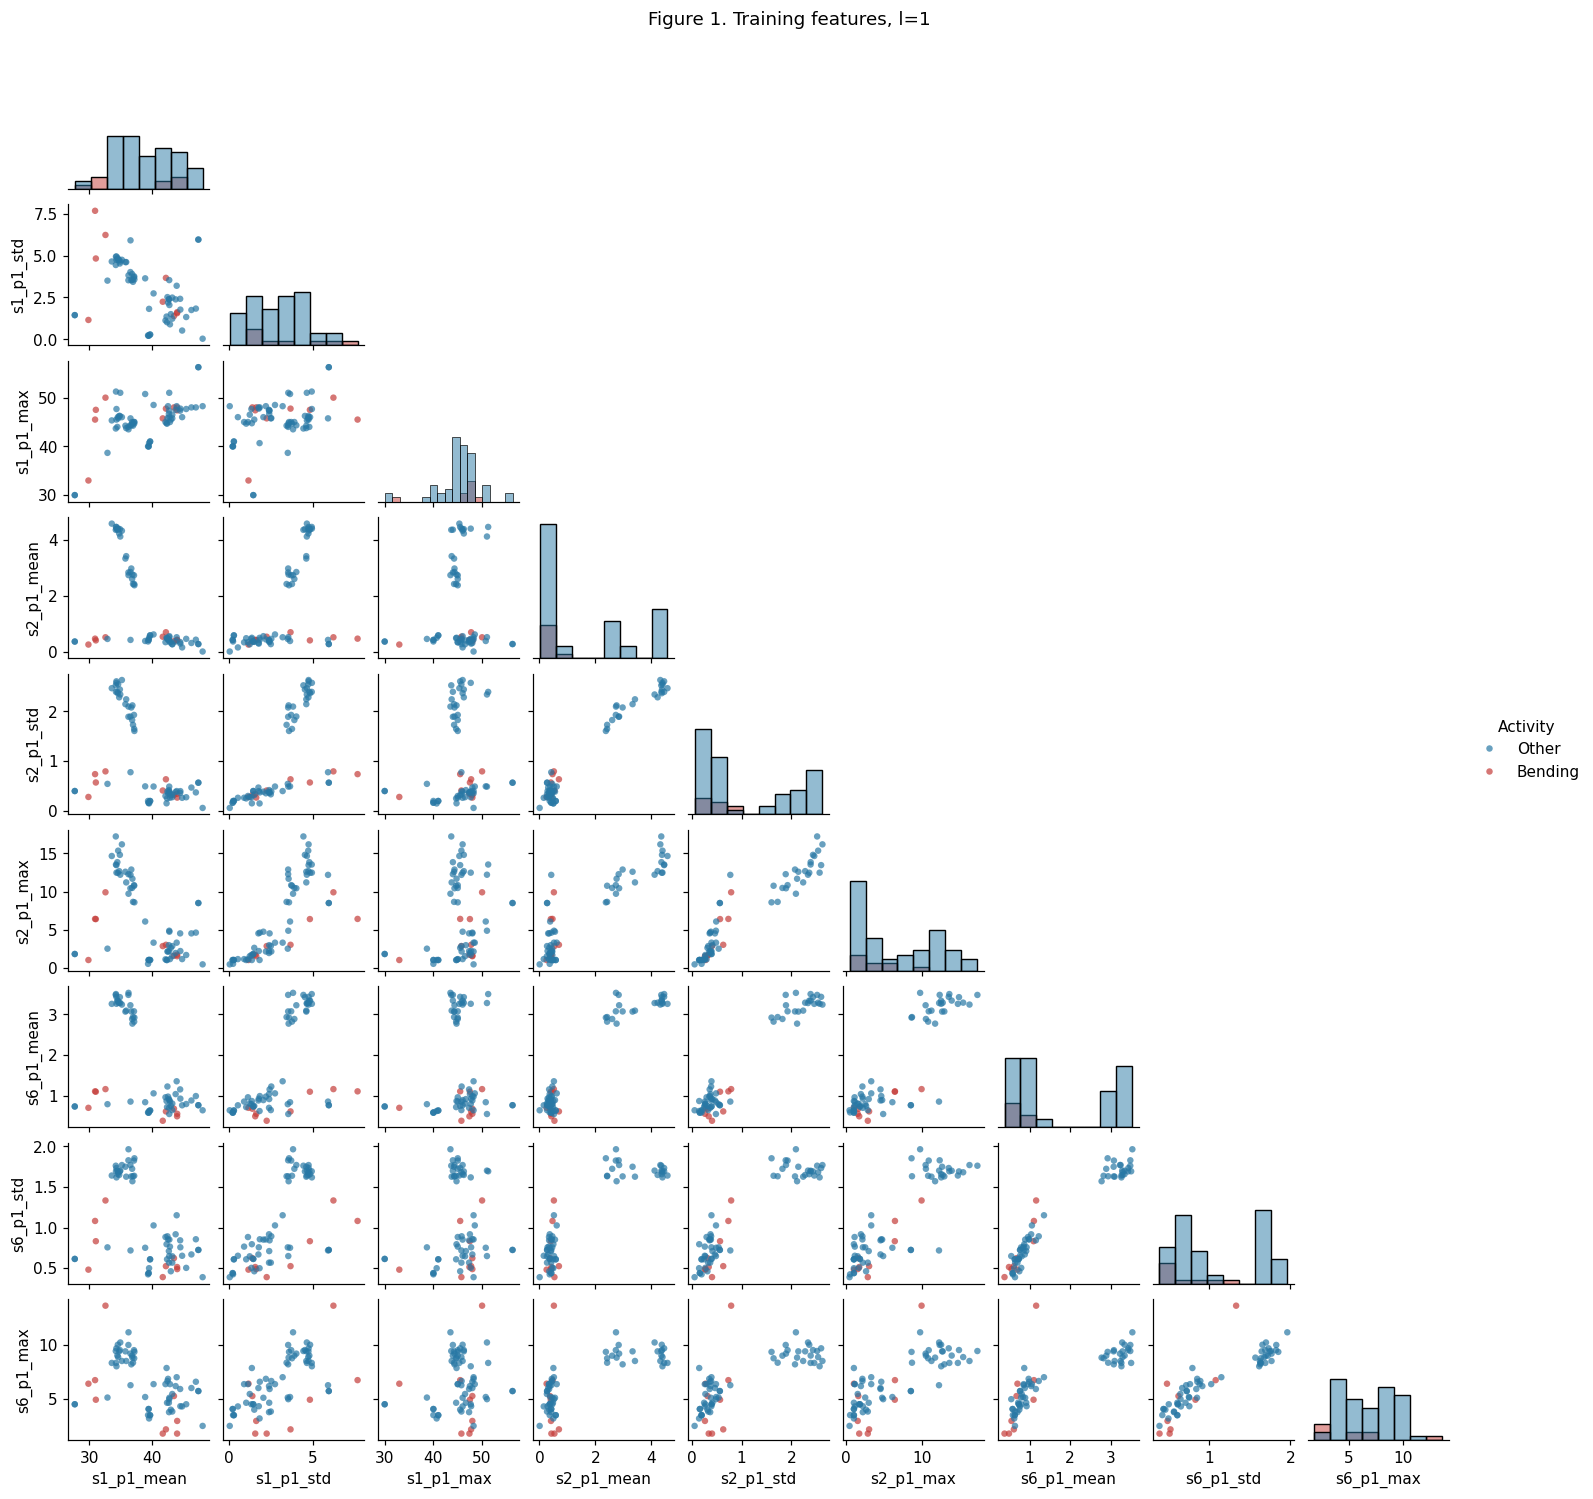

In [4]:
def plot_feature_pairs(number_of_parts, figure_number):
    columns = []
    for part_number in range(1, number_of_parts + 1):
        for series_number in [1, 2, 6]:
            for statistic in SELECTED_STATS:
                columns.append(f"s{series_number}_p{part_number}_{statistic}")

    plot_data = features_by_l[number_of_parts].loc[train_ids, columns].copy()
    plot_data["Activity"] = y_train.map({0: "Other", 1: "Bending"})
    grid = sns.pairplot(plot_data, vars=columns, hue="Activity", hue_order=["Other", "Bending"],
                        palette={"Other": "#2878a5", "Bending": "#c43c39"},
                        diag_kind="hist", corner=True, height=1.5,
                        plot_kws={"s": 18, "alpha": 0.7, "linewidth": 0})
    grid.fig.suptitle(f"Figure {figure_number}. Training features, l={number_of_parts}", y=1.01)
    grid.savefig(RESULT_DIR / f"scatter_l{number_of_parts}.png", dpi=140, bbox_inches="tight")
    plt.show()

plot_feature_pairs(1, 1)

The bending points in Series 2 generally had small averages and standard deviations; however, there were many non-bending recordings that fell into this area as well.

In addition, Series 1 was able to separate some of the bending recordings based upon their lower average, whereas others overlapped with the other types of activity.

Therefore, these two-dimensional representations did not provide a clear distinction between each type of recording.

## 2(a)(ii) Split each series into two parts

The same three statistics from both halves of series 1, 2, and 6 give 18 features for each of the 69 training recordings.

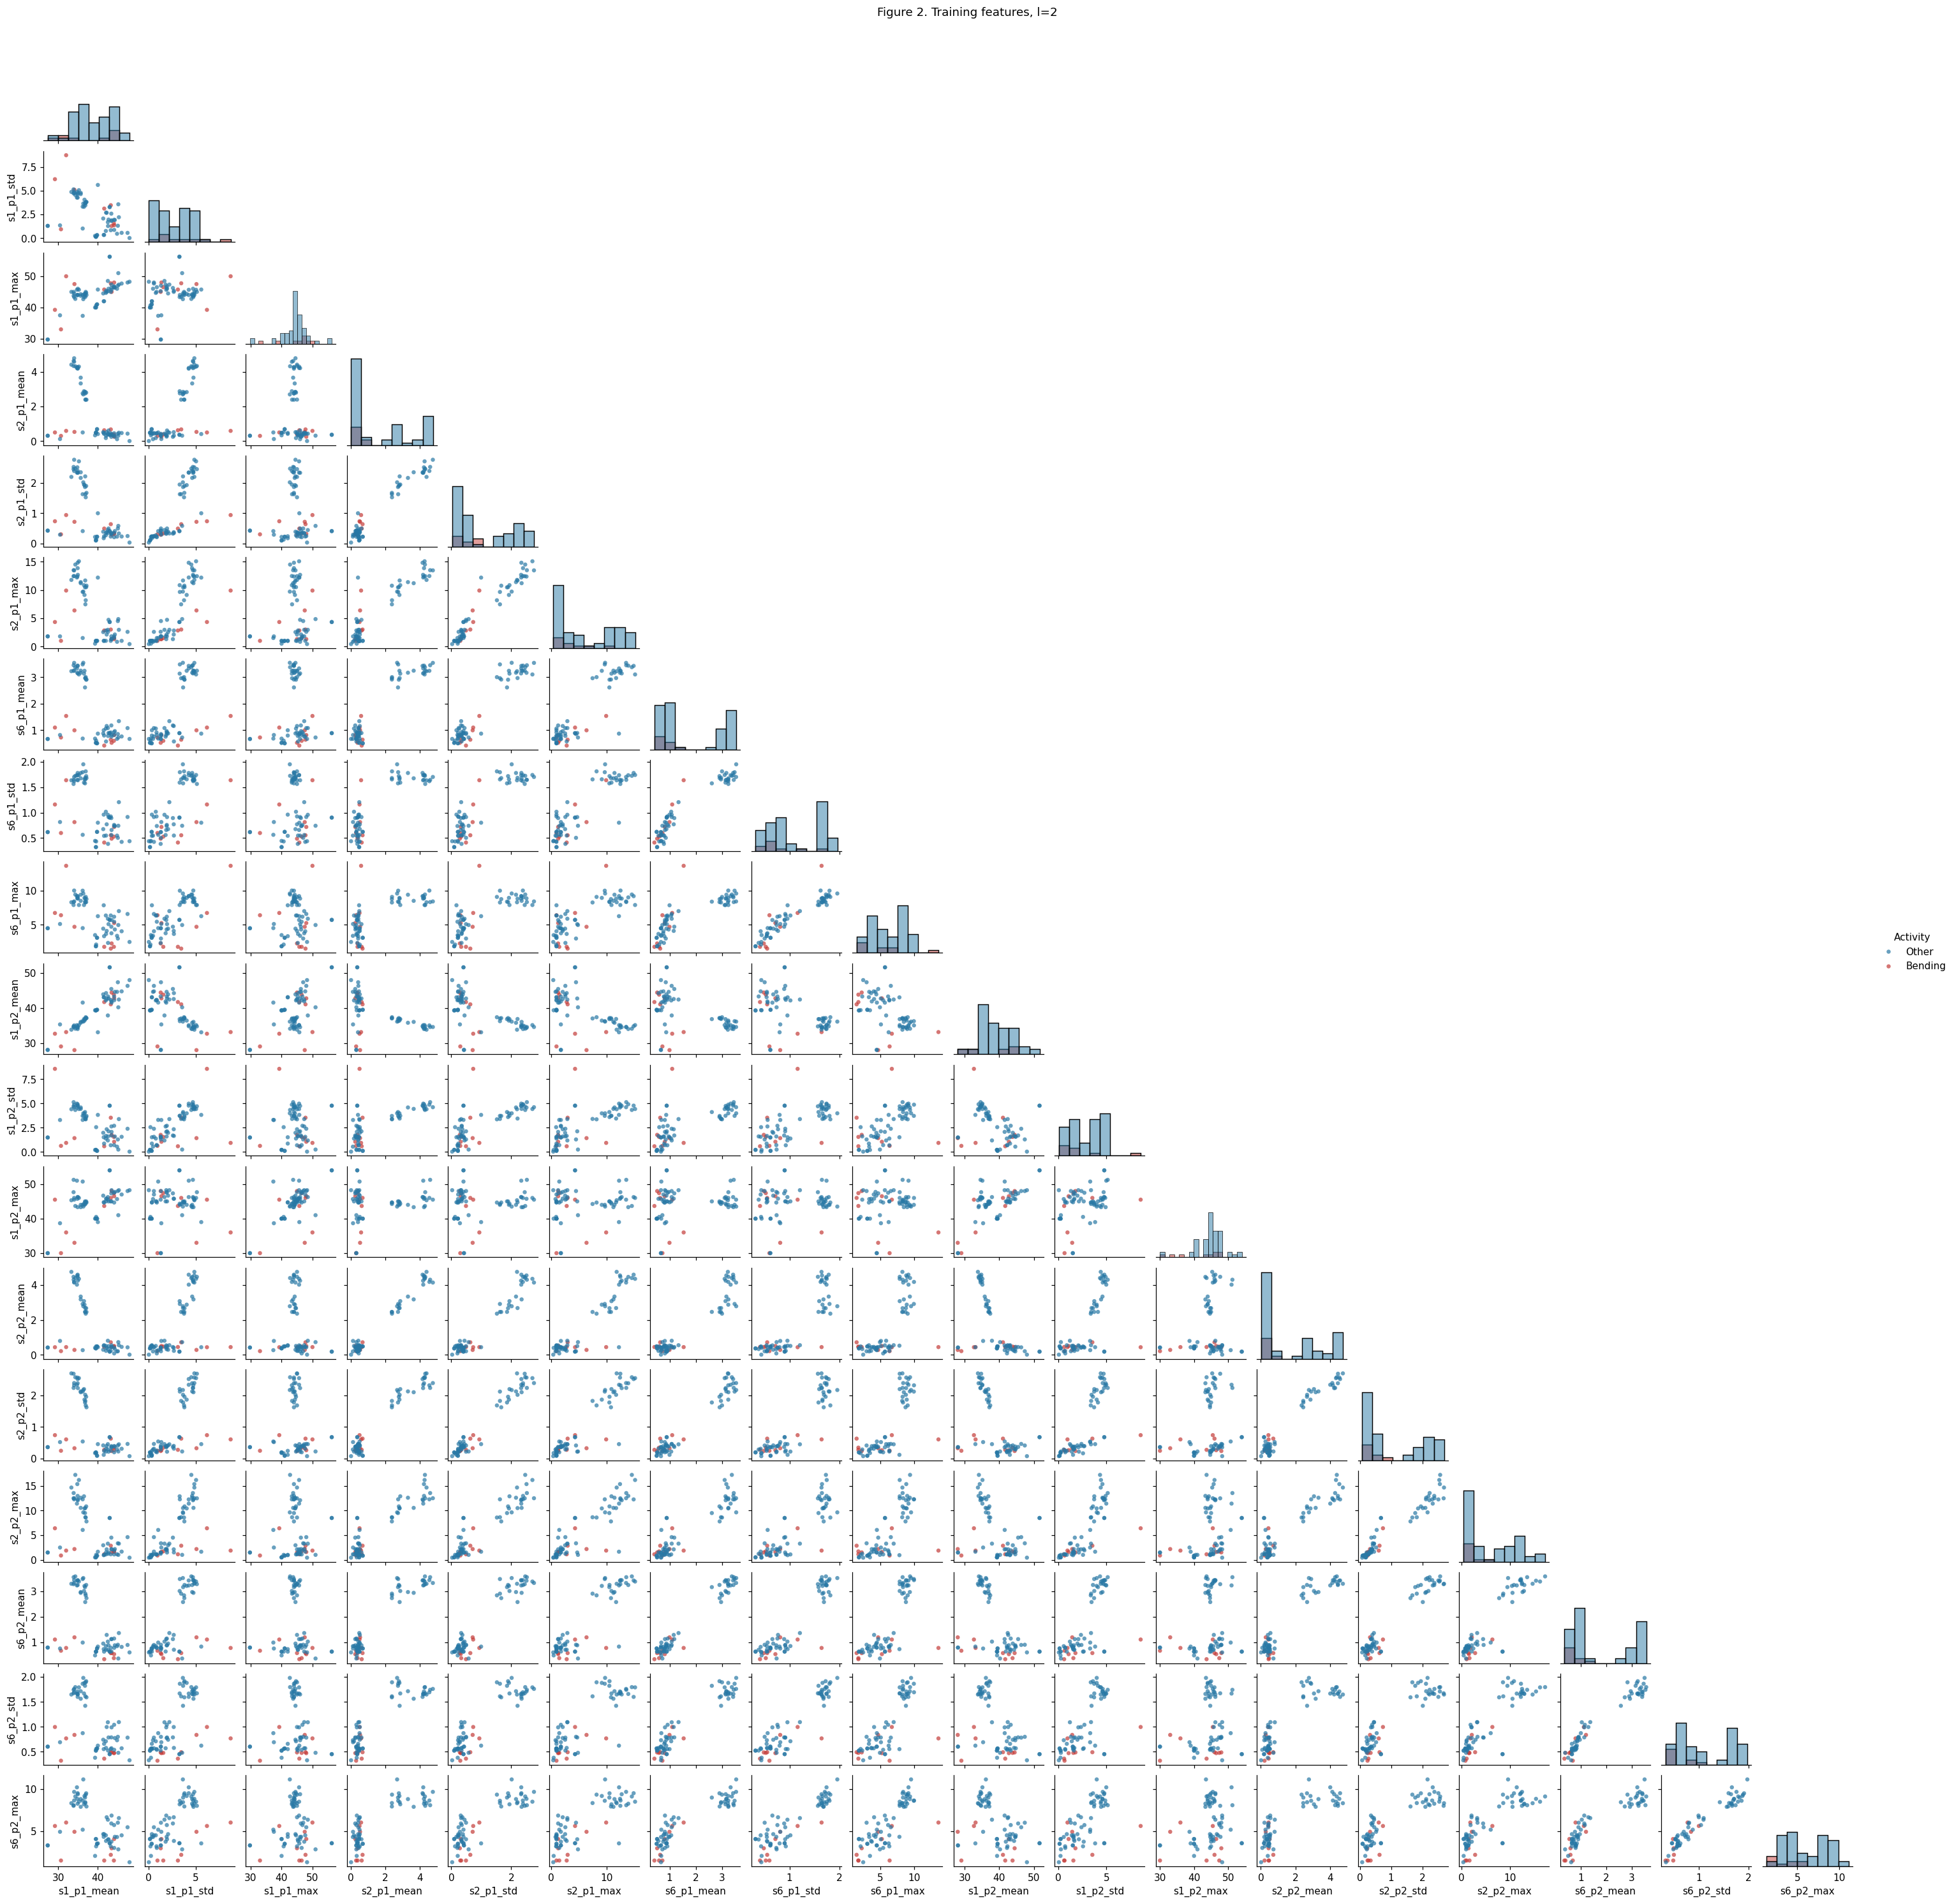

In [5]:
plot_feature_pairs(2, 2)

Dividing into two parts will change many values and show differences within each recording; however, both the low-variability group and the high-variability group are similar. Many of the same-statistic comparisons between the two halves are close to a line which shows there is a lot of overlap. There does not appear to be a large visual improvement in separating the data across the matrix. The additional features may provide value to a fitted model; therefore, I choose the number of segments based on cross-validation (CV) instead of how well the training plots look.

## 2(a)(iii) Select the number of parts and features

I am using the allowed RFE (recursive feature elimination) method as an alternative to p-value based backward selection. I search l = 1, ..., 20 and p = 1, 2, 3, 5, 10, 15, 20, 30. For each fit I use standardization, RFE, and unpenalized logistic regression. I choose the highest five-fold CV accuracy. If there are multiple fits with the same CV accuracy, I choose the one with the smallest p, then the smallest l. The incorrect way to do this is to select features or fit a scaler on all training samples prior to CV. This will leak information from the validation folds. The correct way to do this is to fit both within each CV training fold and evaluate the untouched validation fold. All segments from a recording remain together. Stratified folds approximately maintain the proportion of the 9 bending and 60 other training recordings, so that both classes are represented in each fold. Stratification does not ensure that the classes are balanced. The best CV score may be overly optimistic after searching many different settings.

In [6]:
binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
binary_folds = list(binary_cv.split(np.zeros(len(y_train)), y_train))
for training_rows, validation_rows in binary_folds:
    assert y_train.iloc[training_rows].nunique() == 2
    assert y_train.iloc[validation_rows].nunique() == 2

P_VALUES = [1, 2, 3, 5, 10, 15, 20, 30]
unpenalized = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000, tol=1e-6)
rfe_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("select", RFE(estimator=unpenalized, step=0.2)),
])

def fit_search(search, X, y, label):
    # 保留数值警告的统计，不把未收敛当成正常收敛。
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        search.fit(X, y)
    count = sum(issubclass(item.category, ConvergenceWarning) for item in caught)
    search_warnings.append({"search": label, "convergence_warnings": count})
    return search

rfe_rows = []
for number_of_parts in L_VALUES:
    X = features_by_l[number_of_parts].loc[train_ids]
    search = GridSearchCV(rfe_pipeline, {"select__n_features_to_select": P_VALUES},
                          scoring={"accuracy": "accuracy", "balanced": "balanced_accuracy"},
                          refit=False, cv=binary_folds, n_jobs=1, error_score="raise")
    fit_search(search, X, y_train, f"RFE l={number_of_parts}")
    for index, parameters in enumerate(search.cv_results_["params"]):
        rfe_rows.append({"l": number_of_parts, "p": parameters["select__n_features_to_select"],
                         "cv_accuracy": search.cv_results_["mean_test_accuracy"][index],
                         "cv_sd": search.cv_results_["std_test_accuracy"][index],
                         "cv_balanced_accuracy": search.cv_results_["mean_test_balanced"][index]})
    print(f"RFE search finished: l={number_of_parts}", flush=True)

rfe_results = pd.DataFrame(rfe_rows)
rfe_results = rfe_results.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True])
rfe_results.to_csv(RESULT_DIR / "rfe_cv.csv", index=False)
display(rfe_results.head(10))
best_rfe = rfe_results.iloc[0]
best_l = int(best_rfe["l"])
best_p = int(best_rfe["p"])
X_train_rfe = features_by_l[best_l].loc[train_ids]
X_test_rfe = features_by_l[best_l].loc[test_ids]
rfe_model = clone(rfe_pipeline).set_params(select__n_features_to_select=best_p)
rfe_model.fit(X_train_rfe, y_train)
selected_columns = X_train_rfe.columns[rfe_model.named_steps["select"].support_].tolist()
print("Selected l:", best_l, "Selected p:", best_p)
print("Selected features:", selected_columns)

RFE search finished: l=1


RFE search finished: l=2


RFE search finished: l=3


RFE search finished: l=4


RFE search finished: l=5


...

RFE search finished: l=18


RFE search finished: l=19


RFE search finished: l=20


,l,p,cv_accuracy,cv_sd,cv_balanced_accuracy
19,3,5,0.9714,0.0350,0.9417
43,6,5,0.9714,0.0350,0.9417
148,19,10,0.9714,0.0350,0.9417
149,19,15,0.9714,0.0350,0.9417
159,20,30,0.9714,0.0350,0.9833
4,1,10,0.9703,0.0364,0.8500
16,3,1,0.9571,0.0571,0.8500
85,11,15,0.9571,0.0571,0.9333
62,8,20,0.9571,0.0571,0.8917
86,11,20,0.9571,0.0571,0.9333


Selected l: 3 Selected p: 5
Selected features: ['s1_p1_q1', 's2_p1_max', 's5_p1_max', 's5_p3_min', 's5_p3_max']


The selected pair is **l = 3, p = 5**, with mean CV accuracy **97.14%** and mean balanced accuracy **94.17%**. Several candidates tie on accuracy; the stated tie rule selects the smaller feature count and then the smaller segment count. These are the best settings within the declared candidate grid.

## 2(a)(iv) Training performance, coefficients, and p-values

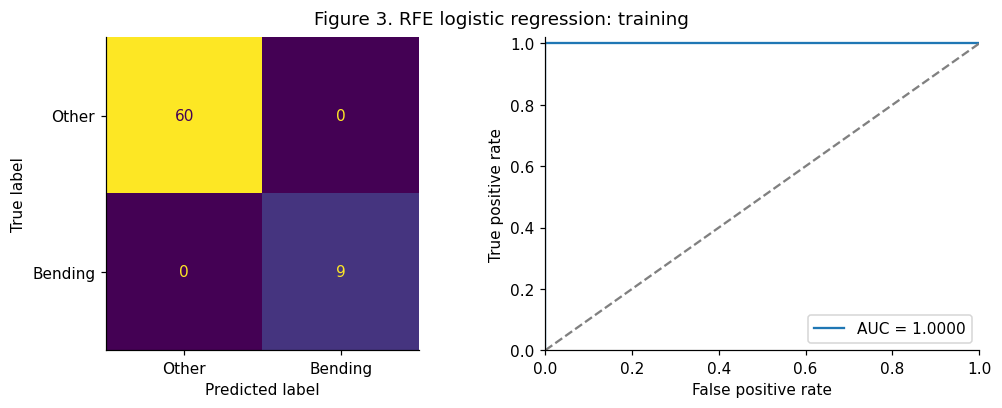

,accuracy,balanced_accuracy,auc
0,1.0,1.0,1.0


In [7]:
def evaluate_binary(y_true, probabilities, title, filename):
    predictions = (probabilities >= 0.5).astype(int)
    matrix = confusion_matrix(y_true, predictions, labels=[0, 1])
    false_positive, true_positive, _ = roc_curve(y_true, probabilities)
    auc = roc_auc_score(y_true, probabilities)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), constrained_layout=True)
    ConfusionMatrixDisplay(matrix, display_labels=["Other", "Bending"]).plot(ax=axes[0], colorbar=False)
    axes[1].plot(false_positive, true_positive, label=f"AUC = {auc:.4f}")
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
    axes[1].legend(loc="lower right")
    fig.suptitle(title)
    fig.savefig(RESULT_DIR / filename, dpi=140)
    plt.show()
    scores = {"accuracy": accuracy_score(y_true, predictions),
              "balanced_accuracy": balanced_accuracy_score(y_true, predictions), "auc": auc}
    display(pd.DataFrame([scores]))
    return scores

rfe_train_prob = rfe_model.predict_proba(X_train_rfe)[:, 1]
rfe_train_scores = evaluate_binary(y_train, rfe_train_prob,
                                  "Figure 3. RFE logistic regression: training", "rfe_train.png")

In [8]:
scaler = rfe_model.named_steps["scale"]
selector = rfe_model.named_steps["select"]
classifier = selector.estimator_
selected_mask = selector.support_
standardized_X = scaler.transform(X_train_rfe)[:, selected_mask]
design = np.column_stack([np.ones(len(y_train)), standardized_X])
coefficients = np.r_[classifier.intercept_[0], classifier.coef_[0]]

# 是否存在一条边界，使每个训练样本都位于正确的一侧？
signed_labels = 2 * y_train.to_numpy() - 1
separation = linprog(np.zeros(design.shape[1]),
                     A_ub=-signed_labels[:, None] * design,
                     b_ub=-np.ones(len(y_train)),
                     bounds=[(None, None)] * design.shape[1], method="highs")
strict_separation = separation.success
weights = rfe_train_prob * (1 - rfe_train_prob)
information = design.T @ (weights[:, None] * design)
full_rank = np.linalg.matrix_rank(design) == design.shape[1]
condition_number = np.linalg.cond(information)
converged = classifier.n_iter_[0] < classifier.max_iter
inference_available = (not strict_separation and full_rank and converged and condition_number < 1e10)
p_values = np.full(len(coefficients), np.nan)
if inference_available:
    standard_errors = np.sqrt(np.diag(np.linalg.inv(information)))
    p_values = 2 * norm.sf(np.abs(coefficients / standard_errors))

raw_slopes = classifier.coef_[0] / scaler.scale_[selected_mask]
raw_intercept = classifier.intercept_[0] - np.dot(raw_slopes, scaler.mean_[selected_mask])
coefficient_table = pd.DataFrame({"feature": ["intercept"] + selected_columns,
                                 "standardized_coefficient": coefficients,
                                 "original_unit_coefficient": np.r_[raw_intercept, raw_slopes],
                                 "wald_p_value": p_values})
display(coefficient_table)
print("Strict separation:", strict_separation)
print("Design full rank:", full_rank, "Information condition number:", condition_number)
print("Finite-fit Wald inference available:", inference_available)
if not inference_available:
    print("NaN p-values mean unavailable: separation, numerical conditioning, or convergence invalidates ordinary inference.")
coefficient_table.to_csv(RESULT_DIR / "rfe_coefficients.csv", index=False)

,feature,standardized_coefficient,original_unit_coefficient,wald_p_value
0,intercept,-33.4679,-65.3540,NaN
1,s1_p1_q1,-6.9935,-1.1734,NaN
2,s2_p1_max,-15.1250,-3.1891,NaN
3,s5_p1_max,21.3099,3.5557,NaN
4,s5_p3_min,14.7882,2.5464,NaN
5,s5_p3_max,-0.6097,-0.1245,NaN


Strict separation: True
Design full rank: True Information condition number: 323.7444983268064
Finite-fit Wald inference available: False
NaN p-values mean unavailable: separation, numerical conditioning, or convergence invalidates ordinary inference.


The chosen model can be completely separated. There were no errors in the training confusion matrix; also, the training AUC was 1.0.
While the coefficients from the stopping rule are numbers that can be calculated, they cannot be used to find a maximum likelihood estimate.
Therefore, all of the standard Wald p-values cannot be calculated (`NaN`). It would be incorrect to say that these values exist or to treat an early-stopped model as if it were a valid inference model.

## 2(a)(v) Held-out binary test performance

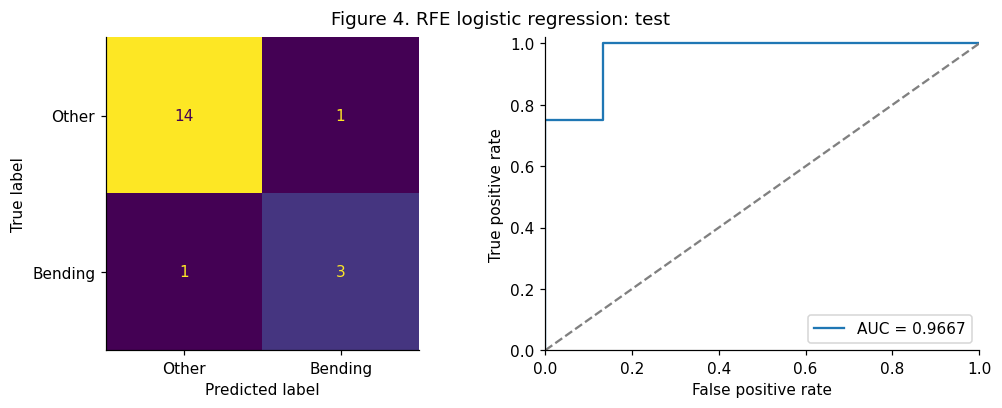

,accuracy,balanced_accuracy,auc
0,0.8947,0.8417,0.9667


,selected_l,selected_p,cv_accuracy,test_accuracy
0,3,5,0.9714,0.8947


In [9]:
rfe_test_prob = rfe_model.predict_proba(X_test_rfe)[:, 1]
rfe_test_scores = evaluate_binary(y_test, rfe_test_prob,
                                 "Figure 4. RFE logistic regression: test", "rfe_test.png")
display(pd.DataFrame([{"selected_l": best_l, "selected_p": best_p,
                       "cv_accuracy": best_rfe["cv_accuracy"],
                       "test_accuracy": rfe_test_scores["accuracy"]}]))

The RFE model accurately identified 17 of 19 (89.47%) test samples; however, this was much less than the 97.14% that were correctly identified using cross validation.
In addition, there were two misclassifications on the test set: one was an actual bending sample which was not recognized as such and the second was a sample that was classified as bending but it wasn't. The area under the ROC curve (AUC) for the test set was 0.9667. This lower than expected accuracy on the held-out data can be attributed to both the limited number of samples available and the large number of potential models considered.

## 2(a)(vi) Separation and numerical stability

In [10]:
stability_rows = []
for tolerance in [1e-4, 1e-6, 1e-8]:
    model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=3000, tol=tolerance)
    model.fit(standardized_X, y_train)
    stability_rows.append({"tolerance": tolerance, "iterations": model.n_iter_[0],
                           "coefficient_norm": np.linalg.norm(model.coef_),
                           "training_accuracy": model.score(standardized_X, y_train)})
stability_table = pd.DataFrame(stability_rows)
display(stability_table)
stability_table.to_csv(RESULT_DIR / "separation_stability.csv", index=False)

,tolerance,iterations,coefficient_norm,training_accuracy
0,1.0000e-04,20,23.8394,1.0
1,1.0000e-06,25,30.8359,1.0
2,1.0000e-08,31,40.5174,1.0


The coefficient norm went up from 23.84 to 40.52 when we made the tolerance tighter; however, our training accuracy remained at 100%. This combined with the separation test shows that although the classification appears to be stable, the coefficient estimates are actually unstable.

## 2(a)(vii) Case-control sampling and intercept correction

The original training data included 9 bending cases and 60 control cases. A simple "all other" classifier was able to achieve 60 out of 69 correct classifications; therefore, both class-specific error rates and balanced accuracy are important. I used all nine bending cases and randomly selected nine control cases (without replacement). This is true case-control sampling, not simply changing the weight of each class. I used the same features that were selected from the entire training set, created a new scaler, and fit an unpenalized logistic model using only the sampled records.

Let $\pi = 9/69$ represent the prevalence of the training data and $\pi_s = 9/18$ represent the prevalence of the sampled data. When sampling based on outcomes, the intercept correction can be calculated as follows:

Training prevalence: 0.13043478260869565 Sample prevalence: 0.5
Intercept adjustment: -1.8971199848858813
Sample intercept: 2.1093316204598724
Corrected intercept: 0.21221163557399114


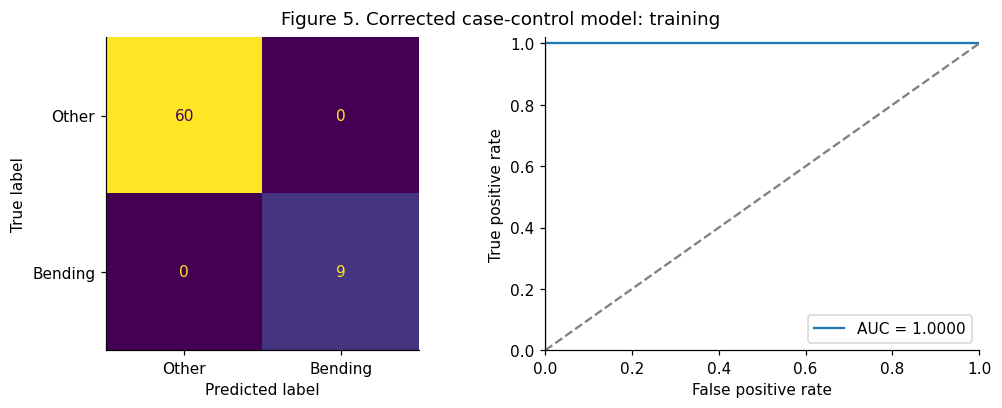

,accuracy,balanced_accuracy,auc
0,1.0,1.0,1.0


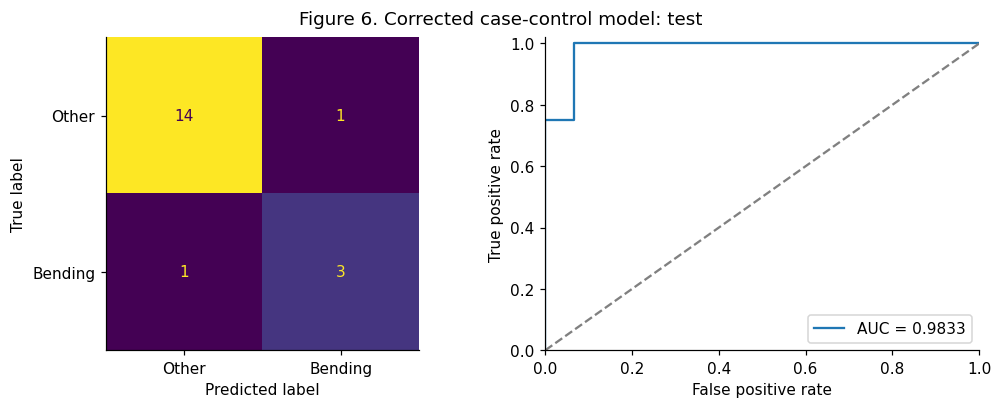

,accuracy,balanced_accuracy,auc
0,0.8947,0.8417,0.9833


,feature,sample_coefficient,corrected_coefficient
0,intercept,2.1093,0.2122
1,s1_p1_q1,-6.9193,-6.9193
2,s2_p1_max,-10.9981,-10.9981
3,s5_p1_max,16.2815,16.2815
4,s5_p3_min,9.1595,9.1595
5,s5_p3_max,-1.8920,-1.8920


In [11]:
rng = np.random.default_rng(SEED)
case_ids = y_train.index[y_train == 1].to_numpy()
control_ids = y_train.index[y_train == 0].to_numpy()
sampled_control_ids = rng.choice(control_ids, size=len(case_ids), replace=False)
sample_ids = np.concatenate([case_ids, sampled_control_ids])

case_scaler = StandardScaler()
sample_X = X_train_rfe.loc[sample_ids, selected_columns]
sample_y = y_train.loc[sample_ids]
scaled_sample = case_scaler.fit_transform(sample_X)
case_model = clone(unpenalized)
case_model.fit(scaled_sample, sample_y)

population_prevalence = y_train.mean()
sample_prevalence = sample_y.mean()
intercept_adjustment = logit(population_prevalence) - logit(sample_prevalence)
print("Training prevalence:", population_prevalence, "Sample prevalence:", sample_prevalence)
print("Intercept adjustment:", intercept_adjustment)
print("Sample intercept:", case_model.intercept_[0])
print("Corrected intercept:", case_model.intercept_[0] + intercept_adjustment)

case_train_X = case_scaler.transform(X_train_rfe[selected_columns])
case_test_X = case_scaler.transform(X_test_rfe[selected_columns])
case_train_prob = expit(case_model.decision_function(case_train_X) + intercept_adjustment)
case_test_prob = expit(case_model.decision_function(case_test_X) + intercept_adjustment)
case_train_scores = evaluate_binary(y_train, case_train_prob,
                                    "Figure 5. Corrected case-control model: training", "case_train.png")
case_test_scores = evaluate_binary(y_test, case_test_prob,
                                   "Figure 6. Corrected case-control model: test", "case_test.png")
case_coefficients = pd.DataFrame({"feature": ["intercept"] + selected_columns,
                                  "sample_coefficient": np.r_[case_model.intercept_[0], case_model.coef_[0]],
                                  "corrected_coefficient": np.r_[case_model.intercept_[0] + intercept_adjustment, case_model.coef_[0]]})
display(case_coefficients)
case_coefficients.to_csv(RESULT_DIR / "case_control_coefficients.csv", index=False)

The confusion matrix row totals show that there are many more "other" recordings (60) than "bending" recordings (9) in the training set, and 15 vs. 4 in the test set.
Therefore, case-control sampling was used with 9 cases and 9 controls. The log-odds correction was approximately -1.8971, which reduced the sampled intercept to account for the lower prevalence of bending in the training set. The corrected model had an accuracy of 89.47% and an AUC of 0.9833 on the test set.
However, its accuracy did not increase relative to the original RFE model on this test split. Discarding controls and fitting separated data can lead to unstable results.

## 2(b)(i) L1-penalized binary logistic regression

I select l from 1 to 20 and C from 0.01, 0.1, 1, 10, and 100 using five-fold stratified CV. Standardization is fitted within each training fold. Ties favor smaller C, then smaller l.

Binary L1 search finished: l=1


Binary L1 search finished: l=2


Binary L1 search finished: l=3


Binary L1 search finished: l=4


Binary L1 search finished: l=5


...

Binary L1 search finished: l=17


Binary L1 search finished: l=18


Binary L1 search finished: l=19


Binary L1 search finished: l=20


,l,cv_accuracy,cv_sd,model__C
57,12,0.9857,0.0286,1.0
87,18,0.9714,0.0350,1.0
58,12,0.9714,0.0350,10.0
63,13,0.9714,0.0350,10.0
88,18,0.9714,0.0350,10.0
59,12,0.9714,0.0350,100.0
89,18,0.9714,0.0350,100.0
12,3,0.9571,0.0571,1.0
3,1,0.9571,0.0571,10.0
53,11,0.9571,0.0350,10.0


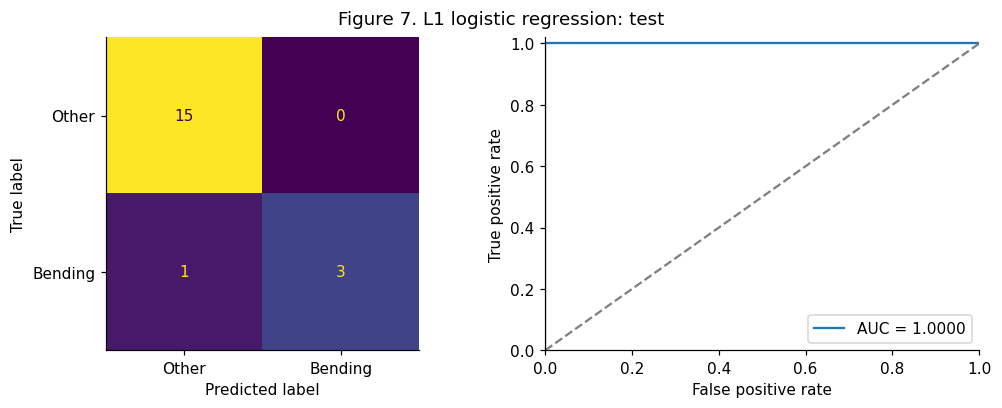

,accuracy,balanced_accuracy,auc
0,0.9474,0.875,1.0


Nonzero coefficients: 5


In [12]:
binary_l1_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(penalty="l1", solver="liblinear", intercept_scaling=100,
                                  max_iter=10000, tol=1e-6, random_state=SEED)),
])

def search_over_segments(pipeline, parameter_grid, target, folds, label):
    result_rows = []
    for number_of_parts in L_VALUES:
        X = features_by_l[number_of_parts].loc[train_ids]
        search = GridSearchCV(pipeline, parameter_grid, scoring="accuracy", cv=folds,
                              refit=False, n_jobs=1, error_score="raise")
        fit_search(search, X, target, f"{label} l={number_of_parts}")
        for index, parameters in enumerate(search.cv_results_["params"]):
            row = {"l": number_of_parts,
                   "cv_accuracy": search.cv_results_["mean_test_score"][index],
                   "cv_sd": search.cv_results_["std_test_score"][index]}
            row.update(parameters)
            result_rows.append(row)
        print(f"{label} search finished: l={number_of_parts}", flush=True)
    return pd.DataFrame(result_rows)

binary_l1_results = search_over_segments(binary_l1_pipeline, {"model__C": C_VALUES},
                                        y_train, binary_folds, "Binary L1")
binary_l1_results = binary_l1_results.sort_values(["cv_accuracy", "model__C", "l"],
                                                ascending=[False, True, True])
binary_l1_results.to_csv(RESULT_DIR / "binary_l1_cv.csv", index=False)
display(binary_l1_results.head(10))
best_binary_l1 = binary_l1_results.iloc[0]
binary_l1_l = int(best_binary_l1["l"])
binary_l1_model = clone(binary_l1_pipeline).set_params(model__C=best_binary_l1["model__C"])
binary_l1_model.fit(features_by_l[binary_l1_l].loc[train_ids], y_train)
binary_l1_prob = binary_l1_model.predict_proba(features_by_l[binary_l1_l].loc[test_ids])[:, 1]
binary_l1_scores = evaluate_binary(y_test, binary_l1_prob,
                                  "Figure 7. L1 logistic regression: test", "binary_l1_test.png")
print("Nonzero coefficients:", np.count_nonzero(binary_l1_model.named_steps["model"].coef_))

## 2(b)(ii) Compare binary models

In [13]:
binary_comparison = pd.DataFrame([
    {"method": "RFE logistic", "l": best_l, "cv_accuracy": best_rfe["cv_accuracy"], **rfe_test_scores},
    {"method": "L1 logistic", "l": binary_l1_l, "cv_accuracy": best_binary_l1["cv_accuracy"], **binary_l1_scores},
    {"method": "Case-control corrected", "l": best_l, "cv_accuracy": np.nan, **case_test_scores},
])
display(binary_comparison)
binary_comparison.to_csv(RESULT_DIR / "binary_comparison.csv", index=False)

,method,l,cv_accuracy,accuracy,balanced_accuracy,auc
0,RFE logistic,3,0.9714,0.8947,0.8417,0.9667
1,L1 logistic,12,0.9857,0.9474,0.8750,1.0000
2,Case-control corrected,3,NaN,0.8947,0.8417,0.9833


The L1 search chose **l = 12, C = 1**. The average CV accuracy of the L1 search was **98.57%**, as opposed to **97.14%** for RFE. The L1 search accurately classified **18 out of 19** test recordings, whereas RFE accurately classified **17 out of 19** test recordings. In this study, the L1 search performed better than RFE on both measures (accuracy and classification) and is easier to apply. The test AUC of the L1 search is **1.0000**; although The test AUC is 1.0, meaning all bending recordings receive higher scores than all non-bending recordings. However, one recording is still misclassified at the 0.5 threshold.

## 2(c)(i) L1-penalized multinomial logistic regression

I fit a seven-class multinomial logistic model with an L1 penalty, selecting l and C over the same grids as in 2(b).
There are only four bending2 recordings in the training set, so one of the five validation folds has no bending2 examples.; however, one of those validation folds did not contain any bending2.
However, every training fold has all seven classes. I will be tuning based on accuracy, which is always defined, and calculating ROC/AUC for each class on the test set (which has all classes). The scaling is done within each training fold. All multiclass methods use the same folds.

In [14]:
multiclass_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
multiclass_folds = list(multiclass_cv.split(np.zeros(len(y_train_multi)), y_train_multi))
fold_counts = []
for training_rows, validation_rows in multiclass_folds:
    assert y_train_multi.iloc[training_rows].nunique() == 7
    fold_counts.append(y_train_multi.iloc[validation_rows].value_counts())
print("Validation class counts (one fold has no bending2 example):")
display(pd.DataFrame(fold_counts).fillna(0).astype(int))

multiclass_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(penalty="l1", solver="saga", multi_class="multinomial",
                                  max_iter=15000, tol=1e-3, random_state=SEED)),
])
multiclass_results = search_over_segments(multiclass_pipeline, {"model__C": C_VALUES},
                                         y_train_multi, multiclass_folds, "Multinomial L1")
multiclass_results = multiclass_results.sort_values(["cv_accuracy", "model__C", "l"],
                                                  ascending=[False, True, True])
multiclass_results.to_csv(RESULT_DIR / "multinomial_l1_cv.csv", index=False)
display(multiclass_results.head(10))
best_multi = multiclass_results.iloc[0]
multi_l = int(best_multi["l"])
multi_model = clone(multiclass_pipeline).set_params(model__C=best_multi["model__C"])
multi_model.fit(features_by_l[multi_l].loc[train_ids], y_train_multi)

Validation class counts (one fold has no bending2 example):


/opt/anaconda3/envs/cse160/lib/python3.10/site-packages/sklearn/model_selection/_split.py:725: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


activity,cycling,standing,lying,sitting,walking,bending1,bending2
count,3,3,2,2,2,1,1
count,2,3,3,2,2,1,1
count,2,2,3,2,3,1,1
count,2,2,2,3,3,1,1
count,3,2,2,3,2,1,0


Multinomial L1 search finished: l=1


Multinomial L1 search finished: l=2


...

Multinomial L1 search finished: l=18


Multinomial L1 search finished: l=19


Multinomial L1 search finished: l=20


,l,cv_accuracy,cv_sd,model__C
2,1,0.9000,0.0857,1.0
19,4,0.9000,0.0571,100.0
29,6,0.9000,0.0571,100.0
82,17,0.8857,0.0728,1.0
97,20,0.8857,0.0571,1.0
14,3,0.8857,0.0728,100.0
24,5,0.8857,0.0728,100.0
59,12,0.8857,0.0728,100.0
39,8,0.8846,0.0337,100.0
89,18,0.8846,0.0564,100.0


Pipeline(steps=[('scale', StandardScaler()),
                ('model',
                 LogisticRegression(max_iter=15000, multi_class='multinomial',
                                    penalty='l1', random_state=42,
                                    solver='saga', tol=0.001))])

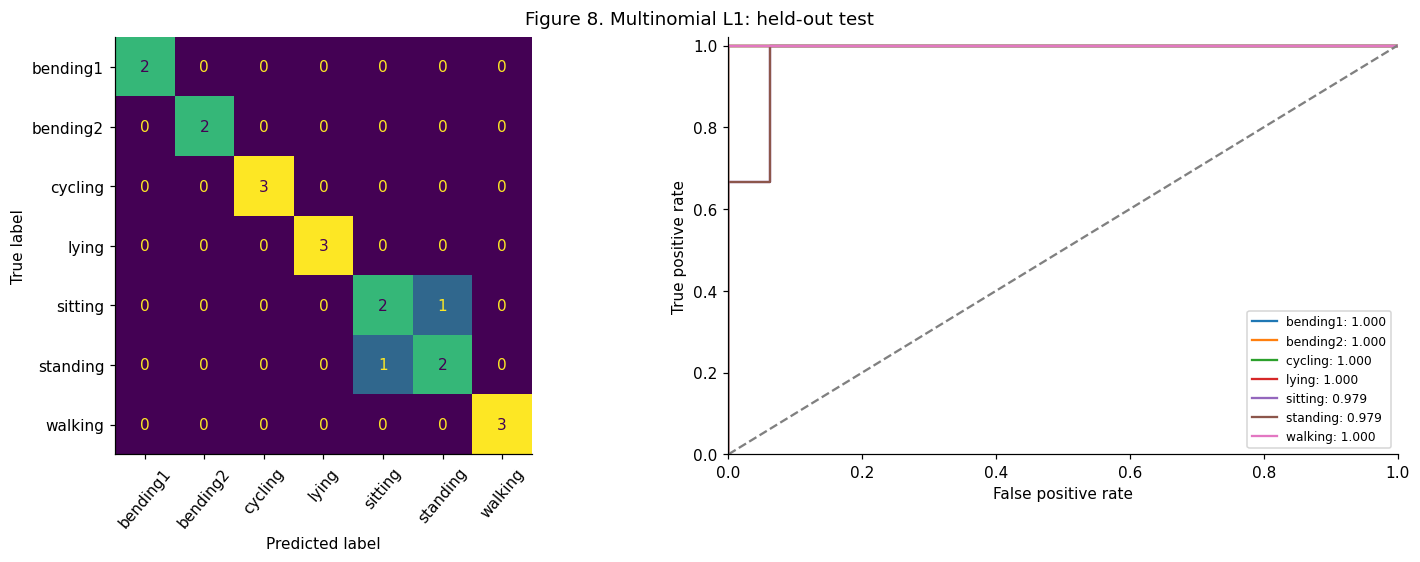

,class,auc
0,bending1,1.0000
1,bending2,1.0000
2,cycling,1.0000
3,lying,1.0000
4,sitting,0.9792
5,standing,0.9792
6,walking,1.0000


,test_accuracy,test_error,macro_auc,micro_auc
0,0.8947,0.1053,0.994,0.9977


In [15]:
def evaluate_multiclass(model, number_of_parts, title, filename):
    X_test = features_by_l[number_of_parts].loc[test_ids]
    probabilities = model.predict_proba(X_test)
    classes = model.classes_
    predictions = model.predict(X_test)
    matrix = confusion_matrix(y_test_multi, predictions, labels=classes)
    indicators = label_binarize(y_test_multi, classes=classes)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
        ax=axes[0], colorbar=False, xticks_rotation=50)
    auc_rows = []
    for index, activity in enumerate(classes):
        fpr, tpr, _ = roc_curve(indicators[:, index], probabilities[:, index])
        auc = roc_auc_score(indicators[:, index], probabilities[:, index])
        auc_rows.append({"class": activity, "auc": auc})
        axes[1].plot(fpr, tpr, label=f"{activity}: {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
    axes[1].legend(fontsize=8, loc="lower right")
    fig.suptitle(title)
    fig.savefig(RESULT_DIR / filename, dpi=140)
    plt.show()
    auc_table = pd.DataFrame(auc_rows)
    display(auc_table)
    accuracy = accuracy_score(y_test_multi, predictions)
    scores = {"test_accuracy": accuracy, "test_error": 1 - accuracy,
              "macro_auc": auc_table["auc"].mean(),
              "micro_auc": roc_auc_score(indicators.ravel(), probabilities.ravel())}
    display(pd.DataFrame([scores]))
    pd.DataFrame(matrix, index=classes, columns=classes).to_csv(RESULT_DIR / filename.replace(".png", "_confusion.csv"))
    auc_table.to_csv(RESULT_DIR / filename.replace(".png", "_auc.csv"), index=False)
    return scores

multi_scores = evaluate_multiclass(multi_model, multi_l,
                                   "Figure 8. Multinomial L1: held-out test", "multinomial_test.png")

## 2(c)(ii) Gaussian and multinomial naive Bayes

I tested l=1...20 through 5-fold cross validation. For GaussianNB, I chose variance smoothing from 1e-9, 1e-6, 1e-3, and 0.1. For MultinomialNB, I chose alpha from 0.01, 0.1, 1, and 10. If there were ties, I chose the smallest value of l first and then the smallest value of smoothing. GaussianNB was standardized using each fold's data. MultinomialNB was scaled using each fold's data with MinMaxScaler and clipped to prevent negative inputs. Continuous summaries like these are better suited for GaussianNB than for the count-based multinomial model. Also, the correlated features will reduce the validity of the conditional independence assumption.

Gaussian NB search finished: l=1


Gaussian NB search finished: l=2


Gaussian NB search finished: l=3


Gaussian NB search finished: l=4


Gaussian NB search finished: l=5


...

Gaussian NB search finished: l=17


Gaussian NB search finished: l=18


Gaussian NB search finished: l=19


Gaussian NB search finished: l=20


,l,cv_accuracy,cv_sd,model__var_smoothing
3,1,0.9132,0.0698,1.0000e-01
2,1,0.8857,0.0857,1.0000e-03
7,2,0.8846,0.0564,1.0000e-01
6,2,0.8714,0.0833,1.0000e-03
0,1,0.8571,0.1278,1.0000e-09
1,1,0.8571,0.1278,1.0000e-06
27,7,0.8407,0.0830,1.0000e-01
23,6,0.8396,0.0729,1.0000e-01
4,2,0.8275,0.0845,1.0000e-09
5,2,0.8275,0.0845,1.0000e-06


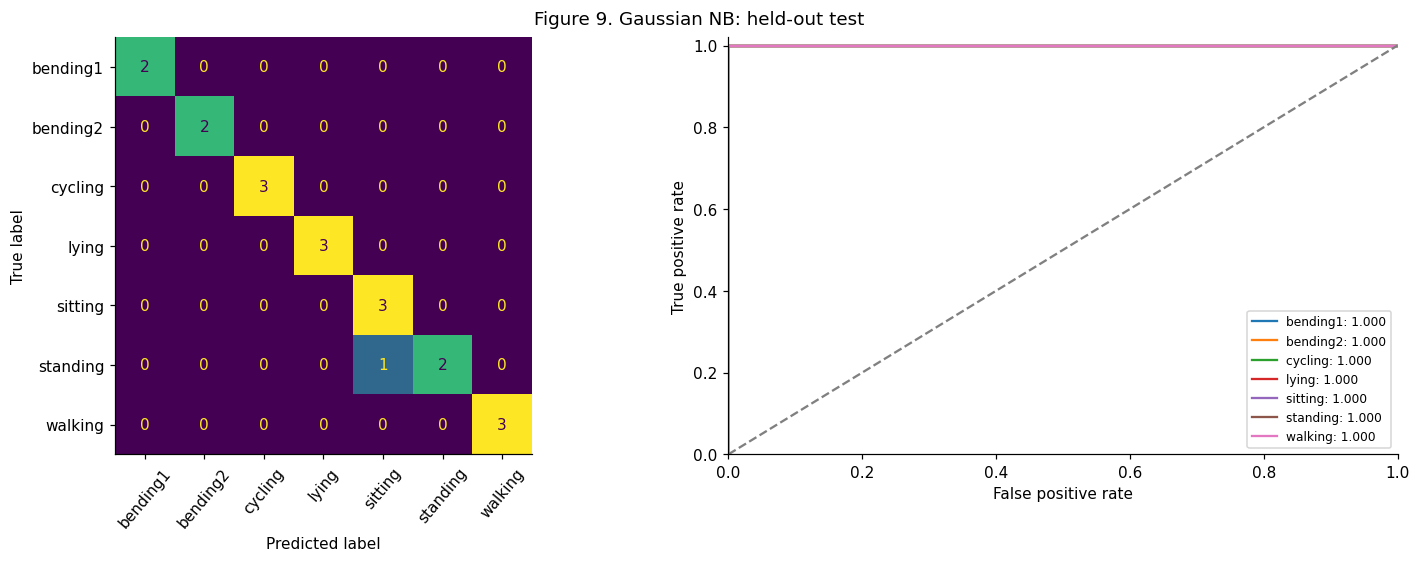

,class,auc
0,bending1,1.0
1,bending2,1.0
2,cycling,1.0
3,lying,1.0
4,sitting,1.0
5,standing,1.0
6,walking,1.0


,test_accuracy,test_error,macro_auc,micro_auc
0,0.9474,0.0526,1.0,0.9995


In [16]:
gaussian_pipeline = Pipeline([("scale", StandardScaler()), ("model", GaussianNB())])
multinomial_nb_pipeline = Pipeline([("scale", MinMaxScaler(clip=True)), ("model", MultinomialNB())])

gaussian_results = search_over_segments(gaussian_pipeline,
                                        {"model__var_smoothing": [1e-9, 1e-6, 1e-3, 0.1]},
                                        y_train_multi, multiclass_folds, "Gaussian NB")
gaussian_results = gaussian_results.sort_values(["cv_accuracy", "l", "model__var_smoothing"],
                                               ascending=[False, True, True])
gaussian_results.to_csv(RESULT_DIR / "gaussian_nb_cv.csv", index=False)
best_gaussian = gaussian_results.iloc[0]
gaussian_l = int(best_gaussian["l"])
gaussian_model = clone(gaussian_pipeline).set_params(model__var_smoothing=best_gaussian["model__var_smoothing"])
gaussian_model.fit(features_by_l[gaussian_l].loc[train_ids], y_train_multi)
display(gaussian_results.head(10))
gaussian_scores = evaluate_multiclass(gaussian_model, gaussian_l,
                                      "Figure 9. Gaussian NB: held-out test", "gaussian_test.png")

Multinomial NB search finished: l=1


Multinomial NB search finished: l=2


Multinomial NB search finished: l=3


Multinomial NB search finished: l=4


Multinomial NB search finished: l=5


...

Multinomial NB search finished: l=17


Multinomial NB search finished: l=18


Multinomial NB search finished: l=19


Multinomial NB search finished: l=20


,l,cv_accuracy,cv_sd,model__alpha
0,1,0.8275,0.0714,0.01
1,1,0.8275,0.0714,0.10
64,17,0.8121,0.1153,0.01
72,19,0.7989,0.1036,0.01
25,7,0.7978,0.0512,0.10
36,10,0.7978,0.1039,0.01
28,8,0.7967,0.0710,0.01
4,2,0.7846,0.0995,0.01
76,20,0.7846,0.1266,0.01
68,18,0.7824,0.1357,0.01


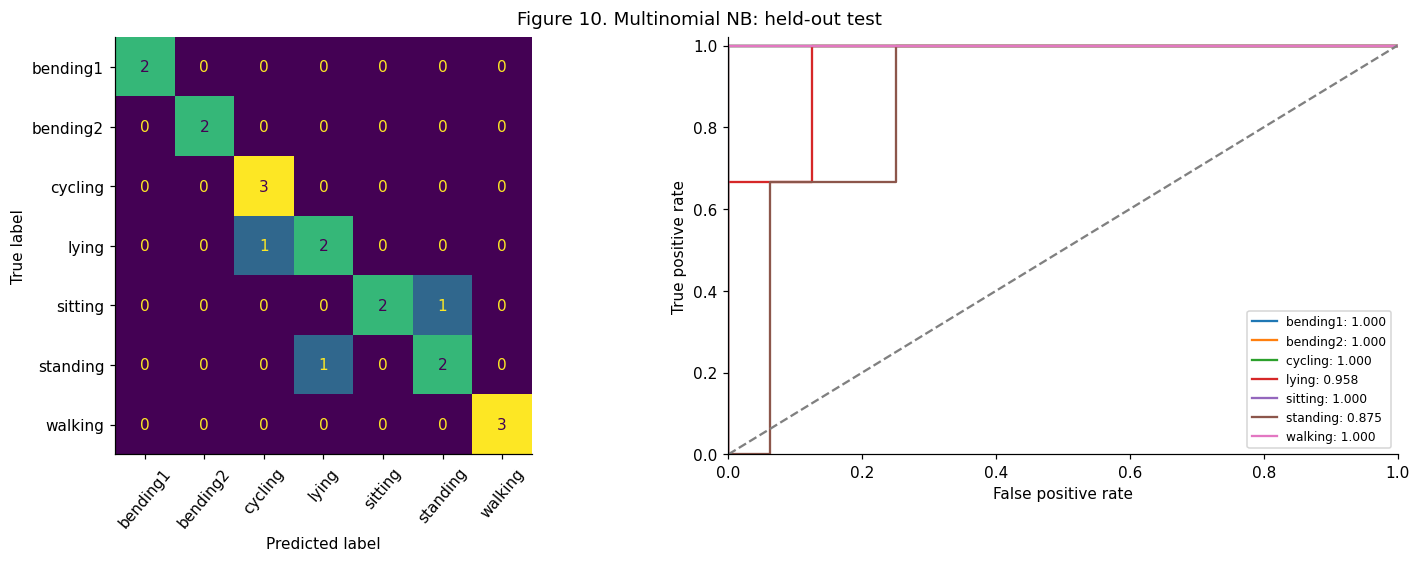

,class,auc
0,bending1,1.0000
1,bending2,1.0000
2,cycling,1.0000
3,lying,0.9583
4,sitting,1.0000
5,standing,0.8750
6,walking,1.0000


,test_accuracy,test_error,macro_auc,micro_auc
0,0.8421,0.1579,0.9762,0.9788


In [17]:
multinomial_nb_results = search_over_segments(multinomial_nb_pipeline,
                                              {"model__alpha": [0.01, 0.1, 1.0, 10.0]},
                                              y_train_multi, multiclass_folds, "Multinomial NB")
multinomial_nb_results = multinomial_nb_results.sort_values(["cv_accuracy", "l", "model__alpha"],
                                                         ascending=[False, True, True])
multinomial_nb_results.to_csv(RESULT_DIR / "multinomial_nb_cv.csv", index=False)
best_nb = multinomial_nb_results.iloc[0]
nb_l = int(best_nb["l"])
nb_model = clone(multinomial_nb_pipeline).set_params(model__alpha=best_nb["model__alpha"])
nb_model.fit(features_by_l[nb_l].loc[train_ids], y_train_multi)
display(multinomial_nb_results.head(10))
nb_scores = evaluate_multiclass(nb_model, nb_l,
                                "Figure 10. Multinomial NB: held-out test", "multinomial_nb_test.png")

## 2(c)(iii) Compare multiclass methods

In [18]:
multiclass_comparison = pd.DataFrame([
    {"method": "Multinomial L1", "l": multi_l, "cv_accuracy": best_multi["cv_accuracy"], **multi_scores},
    {"method": "Gaussian NB", "l": gaussian_l, "cv_accuracy": best_gaussian["cv_accuracy"], **gaussian_scores},
    {"method": "Multinomial NB", "l": nb_l, "cv_accuracy": best_nb["cv_accuracy"], **nb_scores},
])
display(multiclass_comparison)
multiclass_comparison.to_csv(RESULT_DIR / "multiclass_comparison.csv", index=False)
warning_table = pd.DataFrame(search_warnings)
warning_table.to_csv(RESULT_DIR / "search_convergence.csv", index=False)
print("Search fits with convergence warnings:", warning_table["convergence_warnings"].sum())
display(warning_table[warning_table["convergence_warnings"] > 0])

,method,l,cv_accuracy,test_accuracy,test_error,macro_auc,micro_auc
0,Multinomial L1,1,0.9000,0.8947,0.1053,0.9940,0.9977
1,Gaussian NB,1,0.9132,0.9474,0.0526,1.0000,0.9995
2,Multinomial NB,1,0.8275,0.8421,0.1579,0.9762,0.9788


Search fits with convergence warnings: 0


,search,convergence_warnings


The multinomial logistic model selected has **l = 1, C = 1**. GaussianNB has **l = 1** and a variance smoothing of **0.1**; MultinomialNB has **l = 1** and an alpha of **0.01**. The test error rates for each model are **10.53%**, **5.26%**, and **15.79%**, respectively. **GaussianNB is the best performing model** based on its highest cross-validation (CV) accuracy and lowest test error rate.

However, since there are only 19 recordings in the test set, this ranking may not be applicable to other samples.

## 3. ISLR 4.8.3: Why QDA is quadratic

Let $\pi_k=P(Y=k)$ and assume $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$. Bayes' rule assigns x to the class maximizing $\pi_k f_k(x)$, since the denominator is the same for every class. Taking logs and dropping the shared constant $-\tfrac12\log(2\pi)$ gives

$$\delta_k(x)=\log\pi_k-\log\sigma_k-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the square,

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k.$$

The boundary between classes k and j satisfies $\delta_k(x)-\delta_j(x)=0$. Its quadratic coefficient is

$$\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}.$$

When the variance of each group is different, the quadratic term will usually remain in the discriminant and therefore create a quadratic boundary equation. This may result in two boundaries when there is only one variable.

However, if the variance of each group is the same then the quadratic term will be removed from the discriminant and the comparison will reduce to the linear LDA.

Therefore, QDA is typically quadratic; however, there are exceptions where the variance of each group is the same.

## 4. ISLR 4.8.7: Probability of issuing a dividend

Let D denote issuing a dividend. The given values are $P(D)=0.8$, $P(D^c)=0.2$, $\mu_D=10$, $\mu_{D^c}=0$, and $\sigma^2=36$, so the standard deviation is 6. At x=4, Bayes' rule gives

$$P(D\mid X=4)=\frac{0.8\exp[-(4-10)^2/72]}{0.8\exp[-(4-10)^2/72]+0.2\exp[-(4-0)^2/72]}.$$

The identical normal-density constants cancel. The result is approximately **0.7519**, or **75.2%**. Although a profit of 4 is closer to the non-dividend mean of 0, the prior probability of issuing a dividend is much larger.

In [19]:
dividend_density = norm.pdf(4, loc=10, scale=6)
no_dividend_density = norm.pdf(4, loc=0, scale=6)
dividend_probability = (0.8 * dividend_density) / (0.8 * dividend_density + 0.2 * no_dividend_density)
print(f"P(dividend | profit = 4) = {dividend_probability:.6f}")

P(dividend | profit = 4) = 0.751852


## References

1. Course handout, Homework 4, Questions 2-4; supplied AReM data reused from HW3.
2. [scikit-learn LogisticRegression](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.LogisticRegression.html): solver, penalty, and multinomial settings.
3. [scikit-learn RFE](https://scikit-learn.org/1.3/modules/generated/sklearn.feature_selection.RFE.html) and [cross-validation](https://scikit-learn.org/1.3/modules/cross_validation.html): recursive elimination and stratified folds.
4. [scikit-learn naive Bayes](https://scikit-learn.org/1.3/modules/naive_bayes.html): Gaussian and multinomial likelihood models.
5. [statsmodels pitfalls](https://www.statsmodels.org/stable/pitfalls.html): non-existent or non-unique estimates under separation.
6. James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, second edition, Section 4.8, Exercises 3 and 7, pp. 189 and 191. [Authors' website](https://www.statlearning.com/).